In [1]:

from pathlib import Path
from collections import Counter

# Kaggle's attached datasets are usually mounted here.
INPUT_DIR = Path("/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset")

CLASS_NAMES = [
    "glioma",
    "meningioma",
    "notumor",
    "pituitary",
]

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

print("Dataset folders available in Kaggle:\n")

for path in INPUT_DIR.iterdir():
    if path.is_dir():
        print(path.name)

print("\nSearching for the required class folders...")

candidates = []

for path in INPUT_DIR.rglob("*"):
    if not path.is_dir():
        continue

    child_names = {p.name.lower() for p in path.iterdir() if p.is_dir()}

    if set(CLASS_NAMES).issubset(child_names):
        candidates.append(path)

if not candidates:
    print(
        "\nNo directory containing all four classes was found. "
        "Check that the dataset is attached and inspect /kaggle/input."
    )
else:
    for root in candidates:
        print(f"\nPossible dataset split: {root}")

        for class_name in CLASS_NAMES:
            class_dir = root / class_name

            images = [
                p for p in class_dir.rglob("*")
                if p.is_file()
                and p.suffix.lower() in IMAGE_EXTENSIONS
            ]

            print(f"  {class_name:12s}: {len(images):5d} images")


Dataset folders available in Kaggle:

Training
Testing

Searching for the required class folders...

Possible dataset split: /kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Training
  glioma      :  1400 images
  meningioma  :  1400 images
  notumor     :  1400 images
  pituitary   :  1400 images

Possible dataset split: /kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Testing
  glioma      :   400 images
  meningioma  :   400 images
  notumor     :   400 images
  pituitary   :   400 images


In [2]:

import sys
import importlib.util

print("Python version:", sys.version)

packages = [
    "tensorflow",
    "torch",
    "torchvision",
    "numpy",
    "PIL",
    "sklearn",
    "matplotlib",
    "seaborn",
]

for package in packages:
    installed = importlib.util.find_spec(package) is not None
    print(f"{package:15s}: {'Available' if installed else 'Missing'}")

try:
    import torch
    print("\nPyTorch version:", torch.__version__)
    print("CUDA available:", torch.cuda.is_available())

    if torch.cuda.is_available():
        print("GPU:", torch.cuda.get_device_name(0))
except ImportError:
    print("\nPyTorch is not installed.")


Python version: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
tensorflow     : Available
torch          : Available
torchvision    : Available
numpy          : Available
PIL            : Available
sklearn        : Available
matplotlib     : Available
seaborn        : Available

PyTorch version: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4


glioma: Tr-gl_1013.jpg, size=(512, 512), mode=L
glioma: Tr-gl_527.jpg, size=(512, 512), mode=L
glioma: Tr-gl_900.jpg, size=(512, 512), mode=L
meningioma: Tr-me_792.jpg, size=(512, 512), mode=L
meningioma: Tr-me_1040.jpg, size=(512, 512), mode=RGB
meningioma: Tr-me_232.jpg, size=(512, 512), mode=RGB
notumor: Tr-no_1033.jpg, size=(225, 225), mode=RGB
notumor: Tr-no_1319.jpg, size=(236, 270), mode=RGB
notumor: Tr-no_1172.jpg, size=(236, 236), mode=RGB
pituitary: Tr-pi_492.jpg, size=(512, 512), mode=L
pituitary: Tr-pi_1127.jpg, size=(512, 512), mode=L
pituitary: Tr-pi_840.jpg, size=(512, 512), mode=RGB


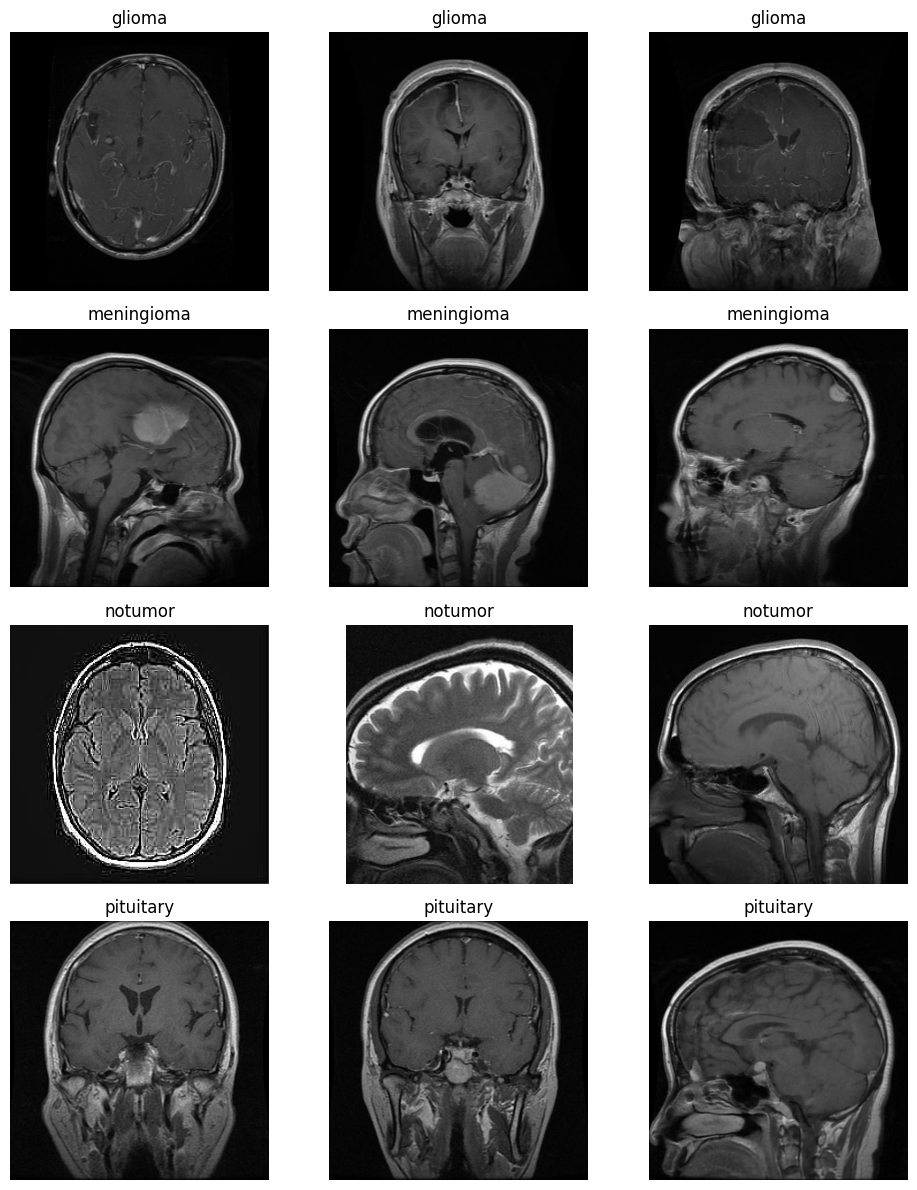

In [3]:

from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import random

DATA_ROOT = Path(
    "/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset"
)

TRAIN_DIR = DATA_ROOT / "Training"
TEST_DIR = DATA_ROOT / "Testing"

CLASS_NAMES = [
    "glioma",
    "meningioma",
    "notumor",
    "pituitary",
]

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

random.seed(42)

fig, axes = plt.subplots(4, 3, figsize=(10, 12))

for row, class_name in enumerate(CLASS_NAMES):
    class_dir = TRAIN_DIR / class_name

    images = [
        p for p in class_dir.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    ]

    selected = random.sample(images, min(3, len(images)))

    for col, image_path in enumerate(selected):
        with Image.open(image_path) as img:
            print(
                f"{class_name}: {image_path.name}, "
                f"size={img.size}, mode={img.mode}"
            )

            axes[row, col].imshow(img.convert("RGB"))
            axes[row, col].set_title(class_name)
            axes[row, col].axis("off")

plt.tight_layout()
plt.show()

In [4]:

import pandas as pd
from sklearn.model_selection import train_test_split

records = []

for class_name in CLASS_NAMES:
    class_dir = TRAIN_DIR / class_name

    for image_path in class_dir.rglob("*"):
        if (
            image_path.is_file()
            and image_path.suffix.lower() in IMAGE_EXTENSIONS
        ):
            records.append({
                "path": str(image_path),
                "label": class_name,
            })

all_train = pd.DataFrame(records)

train_df, val_df = train_test_split(
    all_train,
    test_size=0.20,
    random_state=42,
    stratify=all_train["label"],
)

# Build the untouched official test set.
test_records = []

for class_name in CLASS_NAMES:
    class_dir = TEST_DIR / class_name

    for image_path in class_dir.rglob("*"):
        if (
            image_path.is_file()
            and image_path.suffix.lower() in IMAGE_EXTENSIONS
        ):
            test_records.append({
                "path": str(image_path),
                "label": class_name,
            })

test_df = pd.DataFrame(test_records)

# Save a single shared split definition for both frameworks.
train_df = train_df.copy()
val_df = val_df.copy()
test_df = test_df.copy()

train_df["split"] = "train"
val_df["split"] = "validation"
test_df["split"] = "test"

splits_df = pd.concat(
    [train_df, val_df, test_df],
    ignore_index=True,
)

output_path = "/kaggle/working/splits.csv"
splits_df.to_csv(output_path, index=False)

print("Dataset split counts:")
print(splits_df.groupby(["split", "label"]).size().unstack(fill_value=0))

print("\nTotal images:", len(splits_df))
print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))
print("Saved split file:", output_path)


Dataset split counts:
label       glioma  meningioma  notumor  pituitary
split                                             
test           400         400      400        400
train         1120        1120     1120       1120
validation     280         280      280        280

Total images: 7200
Training: 4480
Validation: 1120
Testing: 1600
Saved split file: /kaggle/working/splits.csv


In [5]:

from PIL import Image

bad_images = []

for split_dir in [TRAIN_DIR, TEST_DIR]:
    for path in split_dir.rglob("*"):
        if not path.is_file():
            continue

        if path.suffix.lower() not in IMAGE_EXTENSIONS:
            continue

        try:
            with Image.open(path) as img:
                img.verify()
        except Exception as exc:
            bad_images.append((str(path), str(exc)))

print("Corrupt or unreadable images:", len(bad_images))

for path, error in bad_images[:10]:
    print(path, "->", error)

if not bad_images:
    print("All images passed the file integrity check.")


Corrupt or unreadable images: 0
All images passed the file integrity check.


In [6]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4


In [7]:

from torchvision import transforms
from PIL import Image
import torch

IMAGE_SIZE = 224

CLASS_NAMES = [
    "glioma",
    "meningioma",
    "notumor",
    "pituitary",
]

# ImageNet normalization for pretrained ResNet weights.
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomRotation(degrees=7),
    transforms.RandomAffine(
        degrees=0,
        translate=(0.03, 0.03),
    ),
    transforms.ColorJitter(brightness=0.08, contrast=0.08),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

print("Image size:", IMAGE_SIZE)
print("Classes:", CLASS_NAMES)
print("Training augmentation: enabled")
print("Validation/test augmentation: disabled")

# Verify that preprocessing produces the expected tensor.
sample_path = train_df.iloc[0]["path"]

with Image.open(sample_path) as img:
    sample_tensor = train_transform(img.convert("RGB"))

print("Sample tensor shape:", tuple(sample_tensor.shape))
print("Sample tensor dtype:", sample_tensor.dtype)
print("Preprocessing ready.")


Image size: 224
Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']
Training augmentation: enabled
Validation/test augmentation: disabled
Sample tensor shape: (3, 224, 224)
Sample tensor dtype: torch.float32
Preprocessing ready.


In [8]:

from pathlib import Path
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from torchvision import transforms

DATA_ROOT = Path(
    "/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset"
)
SPLIT_FILE = Path("/kaggle/working/splits.csv")

CLASS_NAMES = ["glioma", "meningioma", "notumor", "pituitary"]
CLASS_TO_IDX = {name: i for i, name in enumerate(CLASS_NAMES)}
IMAGE_SIZE = 224

if not SPLIT_FILE.exists():
    raise FileNotFoundError(
        "splits.csv is missing. Rerun the split-generation cell first."
    )

splits = pd.read_csv(SPLIT_FILE)

print(splits.groupby(["split", "label"]).size().unstack(fill_value=0))

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomRotation(7),
    transforms.RandomAffine(degrees=0, translate=(0.03, 0.03)),
    transforms.ColorJitter(brightness=0.08, contrast=0.08),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225],
    ),
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225],
    ),
])


class BrainMRIDataset(Dataset):
    def __init__(self, frame, transform):
        self.frame = frame.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]

        with Image.open(row["path"]) as img:
            image = img.convert("RGB")

        image = self.transform(image)
        label = CLASS_TO_IDX[row["label"]]

        return image, label


train_df = splits[splits["split"] == "train"]
val_df = splits[splits["split"] == "validation"]
test_df = splits[splits["split"] == "test"]

train_loader = DataLoader(
    BrainMRIDataset(train_df, train_transform),
    batch_size=32,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available(),
)

val_loader = DataLoader(
    BrainMRIDataset(val_df, eval_transform),
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available(),
)

test_loader = DataLoader(
    BrainMRIDataset(test_df, eval_transform),
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available(),
)

images, labels = next(iter(train_loader))

print("\nTraining batch:", images.shape)
print("Labels batch:", labels.shape)
print("Device:", "cuda" if torch.cuda.is_available() else "cpu")
print("Data loaders are ready.")


label       glioma  meningioma  notumor  pituitary
split                                             
test           400         400      400        400
train         1120        1120     1120       1120
validation     280         280      280        280

Training batch: torch.Size([32, 3, 224, 224])
Labels batch: torch.Size([32])
Device: cuda
Data loaders are ready.


In [9]:

from pathlib import Path
import copy
import torch
import torch.nn as nn
from torchvision.models import resnet18, ResNet18_Weights

# 1. Check the available hardware
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    device = torch.device("cuda")
else:
    device = torch.device("cpu")
    print("WARNING: Training on CPU may be slow.")

# 2. Load ResNet18 with pretrained ImageNet weights
weights = ResNet18_Weights.DEFAULT
model = resnet18(weights=weights)

# 3. Freeze the pretrained backbone
for param in model.parameters():
    param.requires_grad = False

# 4. Replace the original classifier with a 4-class classifier
num_features = model.fc.in_features
model.fc = nn.Linear(num_features, len(CLASS_NAMES))

# The new classification head must be trainable
for param in model.fc.parameters():
    param.requires_grad = True

model = model.to(device)

# 5. Configure training
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(
    model.fc.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

EPOCHS_A = 3
BEST_A_PATH = Path("/kaggle/working/resnet18_strategy_a_best.pt")

best_val_loss = float("inf")
best_val_accuracy = 0.0
history_a = []

# 6. Train and validate
for epoch in range(EPOCHS_A):
    model.train()
    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for batch_images, batch_labels in train_loader:
        batch_images = batch_images.to(device)
        batch_labels = batch_labels.to(device)

        optimizer.zero_grad()
        outputs = model(batch_images)
        loss = criterion(outputs, batch_labels)
        loss.backward()
        optimizer.step()

        train_loss_sum += loss.item() * batch_labels.size(0)
        train_correct += (outputs.argmax(1) == batch_labels).sum().item()
        train_total += batch_labels.size(0)

    train_loss = train_loss_sum / train_total
    train_accuracy = train_correct / train_total

    model.eval()
    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for batch_images, batch_labels in val_loader:
            batch_images = batch_images.to(device)
            batch_labels = batch_labels.to(device)

            outputs = model(batch_images)
            loss = criterion(outputs, batch_labels)

            val_loss_sum += loss.item() * batch_labels.size(0)
            val_correct += (
                outputs.argmax(1) == batch_labels
            ).sum().item()
            val_total += batch_labels.size(0)

    val_loss = val_loss_sum / val_total
    val_accuracy = val_correct / val_total

    history_a.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "val_loss": val_loss,
        "val_accuracy": val_accuracy,
    })

    print(
        f"Epoch {epoch + 1}/{EPOCHS_A} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_val_accuracy = val_accuracy
        torch.save(
            copy.deepcopy(model.state_dict()),
            BEST_A_PATH
        )

print("\nStrategy A complete.")
print("Best validation loss:", round(best_val_loss, 4))
print("Best validation accuracy:", round(best_val_accuracy, 4))
print("Saved model:", BEST_A_PATH)


PyTorch: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 255MB/s]


Epoch 1/3 | Train Loss: 0.7378 | Train Acc: 0.7377 | Val Loss: 0.5239 | Val Acc: 0.8179
Epoch 2/3 | Train Loss: 0.4688 | Train Acc: 0.8342 | Val Loss: 0.4105 | Val Acc: 0.8438
Epoch 3/3 | Train Loss: 0.4048 | Train Acc: 0.8498 | Val Loss: 0.4006 | Val Acc: 0.8446

Strategy A complete.
Best validation loss: 0.4006
Best validation accuracy: 0.8446
Saved model: /kaggle/working/resnet18_strategy_a_best.pt


In [10]:

import copy
import torch
import torch.nn as nn
import pandas as pd
from pathlib import Path
from torchvision.models import resnet18, ResNet18_Weights

BEST_A_PATH = Path("/kaggle/working/resnet18_strategy_a_best.pt")
BEST_B_PATH = Path("/kaggle/working/resnet18_strategy_b_best.pt")

# 1. Load the same pretrained architecture and Strategy A checkpoint
model_b = resnet18(weights=None)
model_b.fc = nn.Linear(model_b.fc.in_features, len(CLASS_NAMES))

model_b.load_state_dict(
    torch.load(BEST_A_PATH, map_location="cpu", weights_only=True)
)

# 2. Freeze all parameters first
for param in model_b.parameters():
    param.requires_grad = False

# 3. Unfreeze the final residual block and classifier
for param in model_b.layer4.parameters():
    param.requires_grad = True

for param in model_b.fc.parameters():
    param.requires_grad = True

model_b = model_b.to(device)

# Use smaller learning rates to carefully fine-tune pretrained features
criterion_b = nn.CrossEntropyLoss()
optimizer_b = torch.optim.AdamW(
    [
        {"params": model_b.layer4.parameters(), "lr": 1e-4},
        {"params": model_b.fc.parameters(), "lr": 5e-4},
    ],
    weight_decay=1e-4,
)

EPOCHS_B = 4
best_val_loss_b = float("inf")
best_val_accuracy_b = 0.0
history_b = []

# 4. Fine-tune and validate
for epoch in range(EPOCHS_B):
    model_b.train()

    # Keep frozen backbone BatchNorm statistics unchanged
    model_b.bn1.eval()
    model_b.layer1.eval()
    model_b.layer2.eval()
    model_b.layer3.eval()

    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for batch_images, batch_labels in train_loader:
        batch_images = batch_images.to(device)
        batch_labels = batch_labels.to(device)

        optimizer_b.zero_grad()
        outputs = model_b(batch_images)
        loss = criterion_b(outputs, batch_labels)
        loss.backward()
        optimizer_b.step()

        train_loss_sum += loss.item() * batch_labels.size(0)
        train_correct += (
            outputs.argmax(1) == batch_labels
        ).sum().item()
        train_total += batch_labels.size(0)

    train_loss = train_loss_sum / train_total
    train_accuracy = train_correct / train_total

    model_b.eval()
    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for batch_images, batch_labels in val_loader:
            batch_images = batch_images.to(device)
            batch_labels = batch_labels.to(device)

            outputs = model_b(batch_images)
            loss = criterion_b(outputs, batch_labels)

            val_loss_sum += loss.item() * batch_labels.size(0)
            val_correct += (
                outputs.argmax(1) == batch_labels
            ).sum().item()
            val_total += batch_labels.size(0)

    val_loss = val_loss_sum / val_total
    val_accuracy = val_correct / val_total

    history_b.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "val_loss": val_loss,
        "val_accuracy": val_accuracy,
    })

    print(
        f"Epoch {epoch + 1}/{EPOCHS_B} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f}"
    )

    if val_loss < best_val_loss_b:
        best_val_loss_b = val_loss
        best_val_accuracy_b = val_accuracy
        torch.save(
            copy.deepcopy(model_b.state_dict()),
            BEST_B_PATH
        )

print("\nStrategy B complete.")
print("Best validation loss:", round(best_val_loss_b, 4))
print("Best validation accuracy:", round(best_val_accuracy_b, 4))
print("Saved model:", BEST_B_PATH)

# 5. Compare the best validation results
comparison = pd.DataFrame([
    {
        "Strategy": "A: Frozen backbone",
        "Best validation loss": best_val_loss,
        "Best validation accuracy": best_val_accuracy,
    },
    {
        "Strategy": "B: Fine-tuned layer4",
        "Best validation loss": best_val_loss_b,
        "Best validation accuracy": best_val_accuracy_b,
    },
])

print("\nStrategy comparison:")
print(comparison.to_string(index=False))


Epoch 1/4 | Train Loss: 0.2506 | Train Acc: 0.9105 | Val Loss: 0.1511 | Val Acc: 0.9464
Epoch 2/4 | Train Loss: 0.1025 | Train Acc: 0.9645 | Val Loss: 0.1313 | Val Acc: 0.9527
Epoch 3/4 | Train Loss: 0.0719 | Train Acc: 0.9730 | Val Loss: 0.1028 | Val Acc: 0.9652
Epoch 4/4 | Train Loss: 0.0489 | Train Acc: 0.9821 | Val Loss: 0.1418 | Val Acc: 0.9545

Strategy B complete.
Best validation loss: 0.1028
Best validation accuracy: 0.9652
Saved model: /kaggle/working/resnet18_strategy_b_best.pt

Strategy comparison:
            Strategy  Best validation loss  Best validation accuracy
  A: Frozen backbone              0.400638                  0.844643
B: Fine-tuned layer4              0.102811                  0.965179


FINAL TEST RESULTS — STRATEGY B
Test images:       1600
Test loss:         0.4407
Test accuracy:     0.9231
Macro precision:   0.9259
Macro recall:      0.9231
Macro F1-score:    0.9219

Per-class classification report:
              precision    recall  f1-score   support

      glioma     0.9463    0.7925    0.8626       400
  meningioma     0.8605    0.9250    0.8916       400
     notumor     0.9070    1.0000    0.9512       400
   pituitary     0.9898    0.9750    0.9824       400

    accuracy                         0.9231      1600
   macro avg     0.9259    0.9231    0.9219      1600
weighted avg     0.9259    0.9231    0.9219      1600



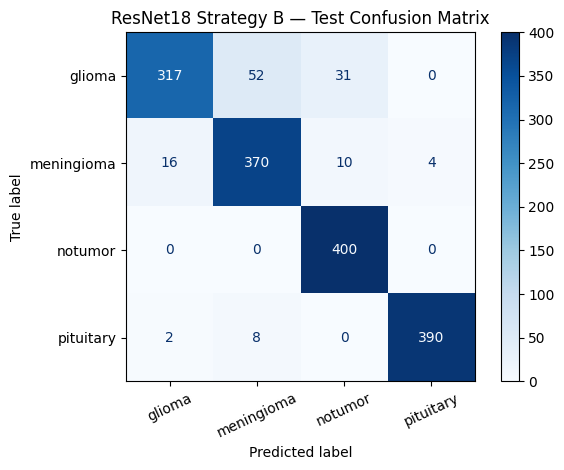

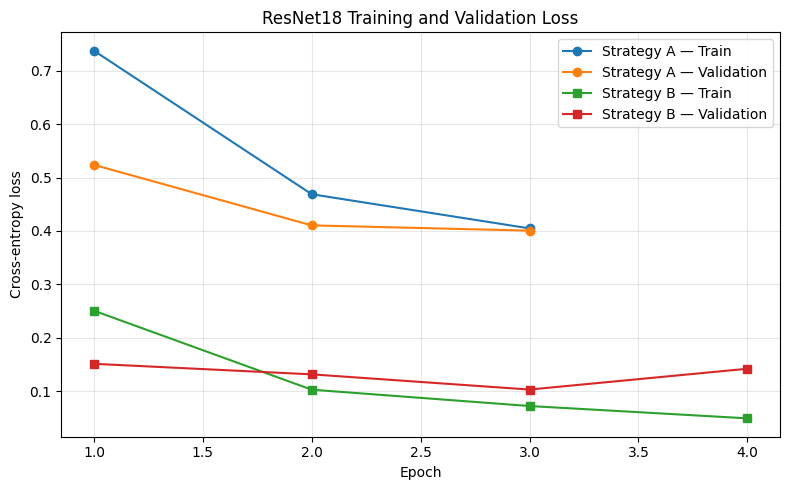


Saved:
/kaggle/working/confusion_matrix_strategy_b.png
/kaggle/working/loss_curves.png
/kaggle/working/test_metrics.csv


In [11]:

import torch
import torch.nn as nn
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from torchvision.models import resnet18
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

# 1. Load the best fine-tuned model
BEST_B_PATH = Path("/kaggle/working/resnet18_strategy_b_best.pt")

test_model = resnet18(weights=None)
test_model.fc = nn.Linear(
    test_model.fc.in_features,
    len(CLASS_NAMES)
)

test_model.load_state_dict(
    torch.load(
        BEST_B_PATH,
        map_location="cpu",
        weights_only=True
    )
)

test_model = test_model.to(device)
test_model.eval()

# 2. Evaluate the test set
y_true = []
y_pred = []
test_loss_sum = 0.0
test_total = 0

criterion_test = nn.CrossEntropyLoss()

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = test_model(images)
        loss = criterion_test(outputs, labels)

        predictions = outputs.argmax(dim=1)

        test_loss_sum += loss.item() * labels.size(0)
        test_total += labels.size(0)

        y_true.extend(labels.cpu().numpy())
        y_pred.extend(predictions.cpu().numpy())

test_loss = test_loss_sum / test_total
test_accuracy = accuracy_score(y_true, y_pred)
test_precision = precision_score(
    y_true, y_pred, average="macro", zero_division=0
)
test_recall = recall_score(
    y_true, y_pred, average="macro", zero_division=0
)
test_f1 = f1_score(
    y_true, y_pred, average="macro", zero_division=0
)

print("FINAL TEST RESULTS — STRATEGY B")
print(f"Test images:       {test_total}")
print(f"Test loss:         {test_loss:.4f}")
print(f"Test accuracy:     {test_accuracy:.4f}")
print(f"Macro precision:   {test_precision:.4f}")
print(f"Macro recall:      {test_recall:.4f}")
print(f"Macro F1-score:    {test_f1:.4f}")

print("\nPer-class classification report:")
print(
    classification_report(
        y_true,
        y_pred,
        labels=list(range(len(CLASS_NAMES))),
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0
    )
)

# 3. Confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(CLASS_NAMES)))
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASS_NAMES
)
display.plot(cmap="Blues", values_format="d")
plt.title("ResNet18 Strategy B — Test Confusion Matrix")
plt.xticks(rotation=25)
plt.tight_layout()
plt.savefig(
    "/kaggle/working/confusion_matrix_strategy_b.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

# 4. Plot training and validation loss curves
history_a_df = pd.DataFrame(history_a)
history_b_df = pd.DataFrame(history_b)

plt.figure(figsize=(8, 5))
plt.plot(
    history_a_df["epoch"],
    history_a_df["train_loss"],
    marker="o",
    label="Strategy A — Train"
)
plt.plot(
    history_a_df["epoch"],
    history_a_df["val_loss"],
    marker="o",
    label="Strategy A — Validation"
)
plt.plot(
    history_b_df["epoch"],
    history_b_df["train_loss"],
    marker="s",
    label="Strategy B — Train"
)
plt.plot(
    history_b_df["epoch"],
    history_b_df["val_loss"],
    marker="s",
    label="Strategy B — Validation"
)

plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("ResNet18 Training and Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
    "/kaggle/working/loss_curves.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

# 5. Save evaluation metrics for the report
metrics = pd.DataFrame([{
    "model": "ResNet18 Strategy B",
    "test_images": test_total,
    "test_loss": test_loss,
    "accuracy": test_accuracy,
    "macro_precision": test_precision,
    "macro_recall": test_recall,
    "macro_f1": test_f1,
}])

metrics.to_csv(
    "/kaggle/working/test_metrics.csv",
    index=False
)

print("\nSaved:")
print("/kaggle/working/confusion_matrix_strategy_b.png")
print("/kaggle/working/loss_curves.png")
print("/kaggle/working/test_metrics.csv")


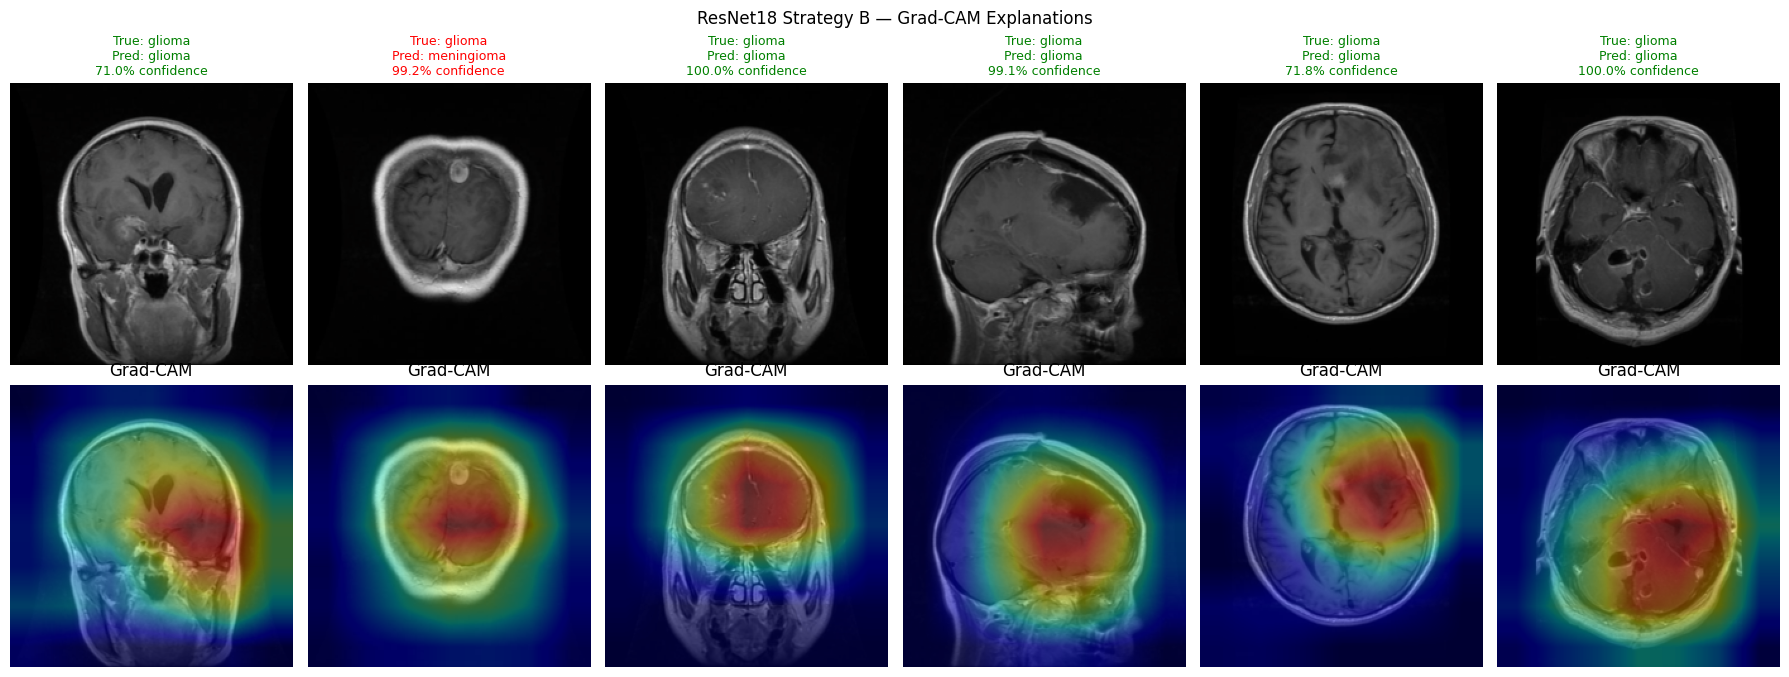

Grad-CAM image saved to: /kaggle/working/gradcam_examples.png
Examples visualized: 6


In [12]:

import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from pathlib import Path
from torchvision.models import resnet18

# 1. Load the best Strategy B checkpoint
BEST_B_PATH = Path("/kaggle/working/resnet18_strategy_b_best.pt")

gradcam_model = resnet18(weights=None)
gradcam_model.fc = nn.Linear(
    gradcam_model.fc.in_features, len(CLASS_NAMES)
)
gradcam_model.load_state_dict(
    torch.load(BEST_B_PATH, map_location="cpu", weights_only=True)
)
gradcam_model = gradcam_model.to(device)
gradcam_model.eval()

# ImageNet normalization values used during training
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

# 2. Generate a Grad-CAM heatmap for one image
def generate_gradcam(image_tensor):
    activations = {}
    gradients = {}

    target_layer = gradcam_model.layer4[-1].conv2

    def forward_hook(module, inputs, output):
        activations["value"] = output
        output.register_hook(
            lambda grad: gradients.update({"value": grad})
        )

    hook = target_layer.register_forward_hook(forward_hook)

    gradcam_model.zero_grad(set_to_none=True)

    input_batch = image_tensor.unsqueeze(0).to(device)
    output = gradcam_model(input_batch)

    predicted_index = int(output.argmax(dim=1).item())
    confidence = float(
        torch.softmax(output, dim=1)[0, predicted_index].item()
    )

    # Explain the predicted class
    score = output[0, predicted_index]
    score.backward()

    feature_maps = activations["value"]
    grads = gradients["value"]

    # Average gradients to obtain the importance of each feature map
    weights = grads.mean(dim=(2, 3), keepdim=True)
    cam = (weights * feature_maps).sum(dim=1, keepdim=True)
    cam = torch.relu(cam)

    cam = torch.nn.functional.interpolate(
        cam,
        size=(IMAGE_SIZE, IMAGE_SIZE),
        mode="bilinear",
        align_corners=False,
    )

    cam = cam[0, 0].detach().cpu().numpy()
    cam_min, cam_max = cam.min(), cam.max()
    cam = (cam - cam_min) / (cam_max - cam_min + 1e-8)

    hook.remove()

    return predicted_index, confidence, cam


# 3. Collect six test examples
examples = []

for batch_images, batch_labels in test_loader:
    for image_tensor, true_label in zip(batch_images, batch_labels):
        predicted_index, confidence, cam = generate_gradcam(image_tensor)

        # Convert normalized tensor back to a displayable RGB image
        rgb = image_tensor.cpu() * std + mean
        rgb = rgb.clamp(0, 1).permute(1, 2, 0).numpy()

        examples.append({
            "image": rgb,
            "true": int(true_label),
            "pred": predicted_index,
            "confidence": confidence,
            "cam": cam,
        })

        if len(examples) >= 6:
            break

    if len(examples) >= 6:
        break

# 4. Plot MRI images beside their Grad-CAM overlays
fig, axes = plt.subplots(2, 6, figsize=(18, 7))

for i, item in enumerate(examples):
    correct = item["true"] == item["pred"]

    axes[0, i].imshow(item["image"])
    axes[0, i].set_title(
        f"True: {CLASS_NAMES[item['true']]}\n"
        f"Pred: {CLASS_NAMES[item['pred']]}\n"
        f"{item['confidence']:.1%} confidence",
        color="green" if correct else "red",
        fontsize=9,
    )
    axes[0, i].axis("off")

    axes[1, i].imshow(item["image"])
    axes[1, i].imshow(item["cam"], cmap="jet", alpha=0.4)
    axes[1, i].set_title("Grad-CAM")
    axes[1, i].axis("off")

plt.suptitle("ResNet18 Strategy B — Grad-CAM Explanations")
plt.tight_layout()

output_path = "/kaggle/working/gradcam_examples.png"
plt.savefig(output_path, dpi=200, bbox_inches="tight")
plt.show()

print("Grad-CAM image saved to:", output_path)
print("Examples visualized:", len(examples))


TensorFlow: 2.20.0
TensorFlow GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
Train: 4480
Validation: 1120
Test: 1600


I0000 00:00:1792956422.318056      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13102 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792956422.321221      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Image batch: (32, 224, 224, 3)
Label batch: (32,)
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         8,196 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

...

 Trainable params: 8,196 (32.02 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

Epoch 1/3
  1/140 ━━━━━━━━━━━━━━━━━━━━ 30:21 13s/step - accuracy: 0.3125 - loss: 1.5444

I0000 00:00:1792956446.474972     342 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step - accuracy: 0.6620 - loss: 0.8694
Epoch 1: val_loss improved from None to 0.35535, saving model to /kaggle/working/tensorflow_resnet50_best.keras

Epoch 1: finished saving model to /kaggle/working/tensorflow_resnet50_best.keras
140/140 ━━━━━━━━━━━━━━━━━━━━ 34s 147ms/step - accuracy: 0.7556 - loss: 0.6299 - val_accuracy: 0.8750 - val_loss: 0.3554
Epoch 2/3
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step - accuracy: 0.8490 - loss: 0.3954
Epoch 2: val_loss improved from 0.35535 to 0.27777, saving model to /kaggle/working/tensorflow_resnet50_best.keras

Epoch 2: finished saving model to /kaggle/working/tensorflow_resnet50_best.keras
140/140 ━━━━━━━━━━━━━━━━━━━━ 17s 123ms/step - accuracy: 0.8585 - loss: 0.3676 - val_accuracy: 0.9027 - val_loss: 0.2778
Epoch 3/3
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step - accuracy: 0.8963 - loss: 0.2879
Epoch 3: val_loss improved from 0.27777 to 0.25212, saving model to /kaggle/working/tensorflow_resnet50_best.keras

Epoch

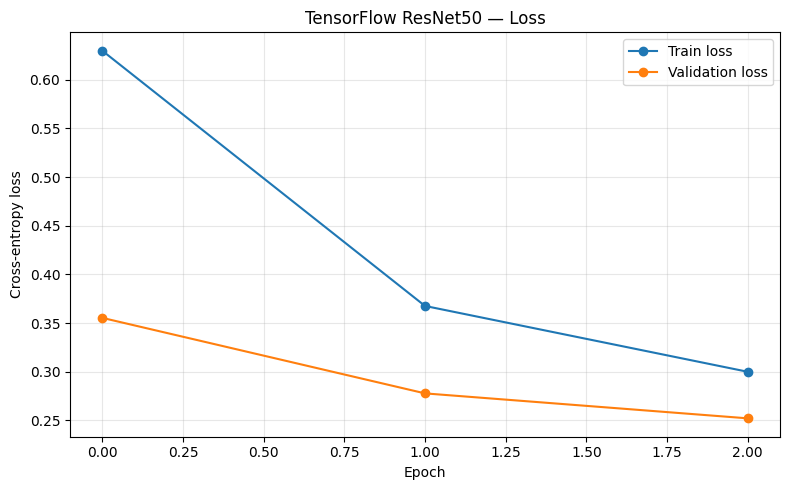

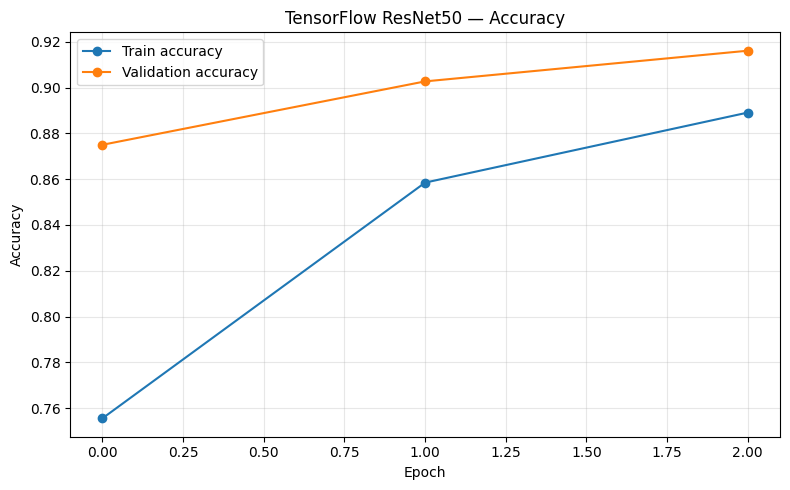

Best model saved to: /kaggle/working/tensorflow_resnet50_best.keras


In [13]:

import tensorflow as tf
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

print("TensorFlow:", tf.__version__)
print("TensorFlow GPUs:", tf.config.list_physical_devices("GPU"))

# 1. Configuration
DATA_SPLIT_PATH = Path("/kaggle/working/splits.csv")
TF_MODEL_PATH = Path("/kaggle/working/tensorflow_resnet50_best.keras")

CLASS_NAMES = ["glioma", "meningioma", "notumor", "pituitary"]
CLASS_TO_IDX = {name: i for i, name in enumerate(CLASS_NAMES)}
IMAGE_SIZE = 224
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

splits_tf = pd.read_csv(DATA_SPLIT_PATH)

train_tf = splits_tf[splits_tf["split"] == "train"].copy()
val_tf = splits_tf[splits_tf["split"] == "validation"].copy()
test_tf = splits_tf[splits_tf["split"] == "test"].copy()

print("Train:", len(train_tf))
print("Validation:", len(val_tf))
print("Test:", len(test_tf))

# 2. Load and preprocess images
def load_tf_image(path, label, training=False):
    image_bytes = tf.io.read_file(path)
    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, [IMAGE_SIZE, IMAGE_SIZE])
    image = tf.cast(image, tf.float32)

    # Augment training images only
    if training:
        image = tf.image.random_flip_left_right(image)
        image = tf.image.random_brightness(image, max_delta=12.0)
        image = tf.image.random_contrast(
            image, lower=0.92, upper=1.08
        )
        image = tf.clip_by_value(image, 0.0, 255.0)

    # ResNet50 has its own ImageNet preprocessing
    image = tf.keras.applications.resnet50.preprocess_input(image)

    return image, label


def make_tf_dataset(frame, training=False):
    paths = frame["path"].astype(str).to_numpy()
    labels = frame["label"].map(CLASS_TO_IDX).to_numpy(
        dtype=np.int32
    )

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        ds = ds.shuffle(
            buffer_size=len(frame),
            seed=42,
            reshuffle_each_iteration=True
        )

    ds = ds.map(
        lambda path, label: load_tf_image(
            path, label, training=training
        ),
        num_parallel_calls=AUTOTUNE
    )
    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(AUTOTUNE)
    return ds


train_ds_tf = make_tf_dataset(train_tf, training=True)
val_ds_tf = make_tf_dataset(val_tf, training=False)
test_ds_tf = make_tf_dataset(test_tf, training=False)

# Verify a batch
for images_batch, labels_batch in train_ds_tf.take(1):
    print("Image batch:", images_batch.shape)
    print("Label batch:", labels_batch.shape)

# 3. Load pretrained ResNet50
base_model_tf = tf.keras.applications.ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3)
)
base_model_tf.trainable = False

# 4. Add a new classifier for our four MRI classes
inputs = tf.keras.Input(
    shape=(IMAGE_SIZE, IMAGE_SIZE, 3)
)
x = base_model_tf(inputs, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.3)(x)
outputs = tf.keras.layers.Dense(
    len(CLASS_NAMES),
    activation="softmax"
)(x)

tf_model = tf.keras.Model(inputs, outputs)

tf_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

tf_model.summary()

# 5. Train the classification head
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        str(TF_MODEL_PATH),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True,
        verbose=1
    )
]

history_tf = tf_model.fit(
    train_ds_tf,
    validation_data=val_ds_tf,
    epochs=3,
    callbacks=callbacks
)

# 6. Plot loss and accuracy curves
history_tf_df = pd.DataFrame(history_tf.history)
history_tf_df.to_csv(
    "/kaggle/working/tensorflow_training_history.csv",
    index=False
)

plt.figure(figsize=(8, 5))
plt.plot(history_tf.history["loss"], marker="o", label="Train loss")
plt.plot(
    history_tf.history["val_loss"],
    marker="o",
    label="Validation loss"
)
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("TensorFlow ResNet50 — Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
    "/kaggle/working/tensorflow_loss_curves.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(
    history_tf.history["accuracy"],
    marker="o",
    label="Train accuracy"
)
plt.plot(
    history_tf.history["val_accuracy"],
    marker="o",
    label="Validation accuracy"
)
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("TensorFlow ResNet50 — Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
    "/kaggle/working/tensorflow_accuracy_curves.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

print("Best model saved to:", TF_MODEL_PATH)


In [14]:

import tensorflow as tf
from pathlib import Path

BASE_PATH = Path("/kaggle/working/tensorflow_resnet50_best.keras")
FINE_TUNED_PATH = Path("/kaggle/working/tensorflow_resnet50_strategy_b_best.keras")

# Load the best model from Strategy A
tf_model_b = tf.keras.models.load_model(BASE_PATH)

# Find the pretrained ResNet50 backbone inside the model
base_model_b = None
for layer in tf_model_b.layers:
    if isinstance(layer, tf.keras.Model) and "resnet50" in layer.name.lower():
        base_model_b = layer
        break

if base_model_b is None:
    raise ValueError("Could not find the ResNet50 backbone in the loaded model.")

# Unfreeze the backbone, then freeze everything except the final block
base_model_b.trainable = True

for layer in base_model_b.layers:
    layer.trainable = False

for layer in base_model_b.layers:
    if layer.name.startswith("conv5_block3"):
        layer.trainable = True

# Keep BatchNormalization layers frozen for stable fine-tuning
for layer in base_model_b.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

# Compile again after changing trainable layers
tf_model_b.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

tf_model_b.summary()

callbacks_b = [
    tf.keras.callbacks.ModelCheckpoint(
        str(FINE_TUNED_PATH),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True,
        verbose=1
    )
]

history_tf_b = tf_model_b.fit(
    train_ds_tf,
    validation_data=val_ds_tf,
    epochs=4,
    callbacks=callbacks_b
)

print("TensorFlow Strategy B complete.")
print("Best fine-tuned model:", FINE_TUNED_PATH)


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         8,196 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,595,908 (90.01 MB)

 Trainable params: 4,467,716 (17.04 MB)

 Non-trainable params: 19,128,192 (72.97 MB)

Epoch 1/4
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - accuracy: 0.9004 - loss: 0.2559
Epoch 1: val_loss improved from None to 0.21781, saving model to /kaggle/working/tensorflow_resnet50_strategy_b_best.keras

Epoch 1: finished saving model to /kaggle/working/tensorflow_resnet50_strategy_b_best.keras
140/140 ━━━━━━━━━━━━━━━━━━━━ 34s 154ms/step - accuracy: 0.9049 - loss: 0.2528 - val_accuracy: 0.9214 - val_loss: 0.2178
Epoch 2/4
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 101ms/step - accuracy: 0.9235 - loss: 0.2099
Epoch 2: val_loss improved from 0.21781 to 0.19847, saving model to /kaggle/working/tensorflow_resnet50_strategy_b_best.keras

Epoch 2: finished saving model to /kaggle/working/tensorflow_resnet50_strategy_b_best.keras
140/140 ━━━━━━━━━━━━━━━━━━━━ 19s 132ms/step - accuracy: 0.9232 - loss: 0.2084 - val_accuracy: 0.9259 - val_loss: 0.1985
Epoch 3/4
140/140 ━━━━━━━━━━━━━━━━━━━━ 0s 101ms/step - accuracy: 0.9365 - loss: 0.1875
Epoch 3: val_loss improved from 0.19847 to 0.18294, saving model 

50/50 ━━━━━━━━━━━━━━━━━━━━ 8s 83ms/step
TENSORFLOW RESNET50 STRATEGY B — TEST RESULTS
Test images: 1600
Test loss:       0.4333
Test accuracy:   0.8906
Macro precision: 0.8989
Macro recall:    0.8906
Macro F1-score:  0.8880

Per-class report:
              precision    recall  f1-score   support

      glioma     0.9621    0.6975    0.8087       400
  meningioma     0.7766    0.8950    0.8316       400
     notumor     0.9145    0.9900    0.9508       400
   pituitary     0.9423    0.9800    0.9608       400

    accuracy                         0.8906      1600
   macro avg     0.8989    0.8906    0.8880      1600
weighted avg     0.8989    0.8906    0.8880      1600



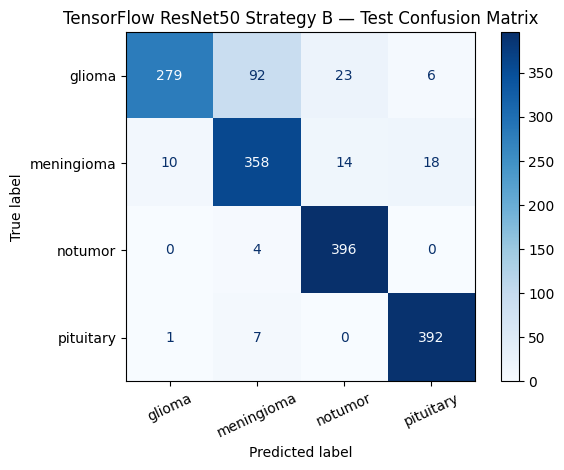


Saved test metrics and confusion matrix.


In [15]:

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

# Load the best fine-tuned TensorFlow model
MODEL_PATH = (
    "/kaggle/working/"
    "tensorflow_resnet50_strategy_b_best.keras"
)
best_tf_model = tf.keras.models.load_model(MODEL_PATH)

# Predict using the untouched test dataset
test_probabilities = best_tf_model.predict(
    test_ds_tf,
    verbose=1
)
y_pred_tf = np.argmax(test_probabilities, axis=1)

# Extract true labels in the same order
y_true_tf = np.concatenate([
    labels.numpy()
    for _, labels in test_ds_tf
])

assert len(y_true_tf) == len(y_pred_tf), (
    "Mismatch between test labels and predictions."
)

# Calculate loss and classification metrics
test_loss_tf, _ = best_tf_model.evaluate(
    test_ds_tf,
    verbose=0
)

test_accuracy_tf = accuracy_score(y_true_tf, y_pred_tf)
test_precision_tf = precision_score(
    y_true_tf, y_pred_tf, average="macro", zero_division=0
)
test_recall_tf = recall_score(
    y_true_tf, y_pred_tf, average="macro", zero_division=0
)
test_f1_tf = f1_score(
    y_true_tf, y_pred_tf, average="macro", zero_division=0
)

print("TENSORFLOW RESNET50 STRATEGY B — TEST RESULTS")
print("Test images:", len(y_true_tf))
print(f"Test loss:       {test_loss_tf:.4f}")
print(f"Test accuracy:   {test_accuracy_tf:.4f}")
print(f"Macro precision: {test_precision_tf:.4f}")
print(f"Macro recall:    {test_recall_tf:.4f}")
print(f"Macro F1-score:  {test_f1_tf:.4f}")

print("\nPer-class report:")
print(classification_report(
    y_true_tf,
    y_pred_tf,
    labels=list(range(len(CLASS_NAMES))),
    target_names=CLASS_NAMES,
    digits=4,
    zero_division=0,
))

# Plot and save the confusion matrix
cm_tf = confusion_matrix(
    y_true_tf,
    y_pred_tf,
    labels=list(range(len(CLASS_NAMES))),
)

ConfusionMatrixDisplay(
    confusion_matrix=cm_tf,
    display_labels=CLASS_NAMES,
).plot(cmap="Blues", values_format="d")

plt.title("TensorFlow ResNet50 Strategy B — Test Confusion Matrix")
plt.xticks(rotation=25)
plt.tight_layout()
plt.savefig(
    "/kaggle/working/tensorflow_strategy_b_confusion_matrix.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

# Save metrics for the report
tf_metrics = pd.DataFrame([{
    "model": "TensorFlow ResNet50 Strategy B",
    "test_images": len(y_true_tf),
    "test_loss": test_loss_tf,
    "accuracy": test_accuracy_tf,
    "macro_precision": test_precision_tf,
    "macro_recall": test_recall_tf,
    "macro_f1": test_f1_tf,
}])

tf_metrics.to_csv(
    "/kaggle/working/tensorflow_strategy_b_test_metrics.csv",
    index=False,
)

print("\nSaved test metrics and confusion matrix.")


In [16]:

import tensorflow as tf

model = tf.keras.models.load_model(
    "/kaggle/working/tensorflow_resnet50_strategy_b_best.keras"
)

print("Model layers:")
for i, layer in enumerate(model.layers):
    print(i, layer.name, type(layer).__name__)

print("\nNested ResNet models:")
for layer in model.layers:
    if isinstance(layer, tf.keras.Model):
        print("Backbone:", layer.name)
        print("Input shape:", layer.input_shape)
        print("Output shape:", layer.output_shape)
        print("Target convolution layer:")
        layer.get_layer("conv5_block3_out")
        print("conv5_block3_out found successfully")


Model layers:
0 input_layer_1 InputLayer
1 resnet50 Functional
2 global_average_pooling2d GlobalAveragePooling2D
3 dropout Dropout
4 dense Dense

Nested ResNet models:
Backbone: resnet50
Input shape: (None, 224, 224, 3)
Output shape: (None, 7, 7, 2048)
Target convolution layer:
conv5_block3_out found successfully


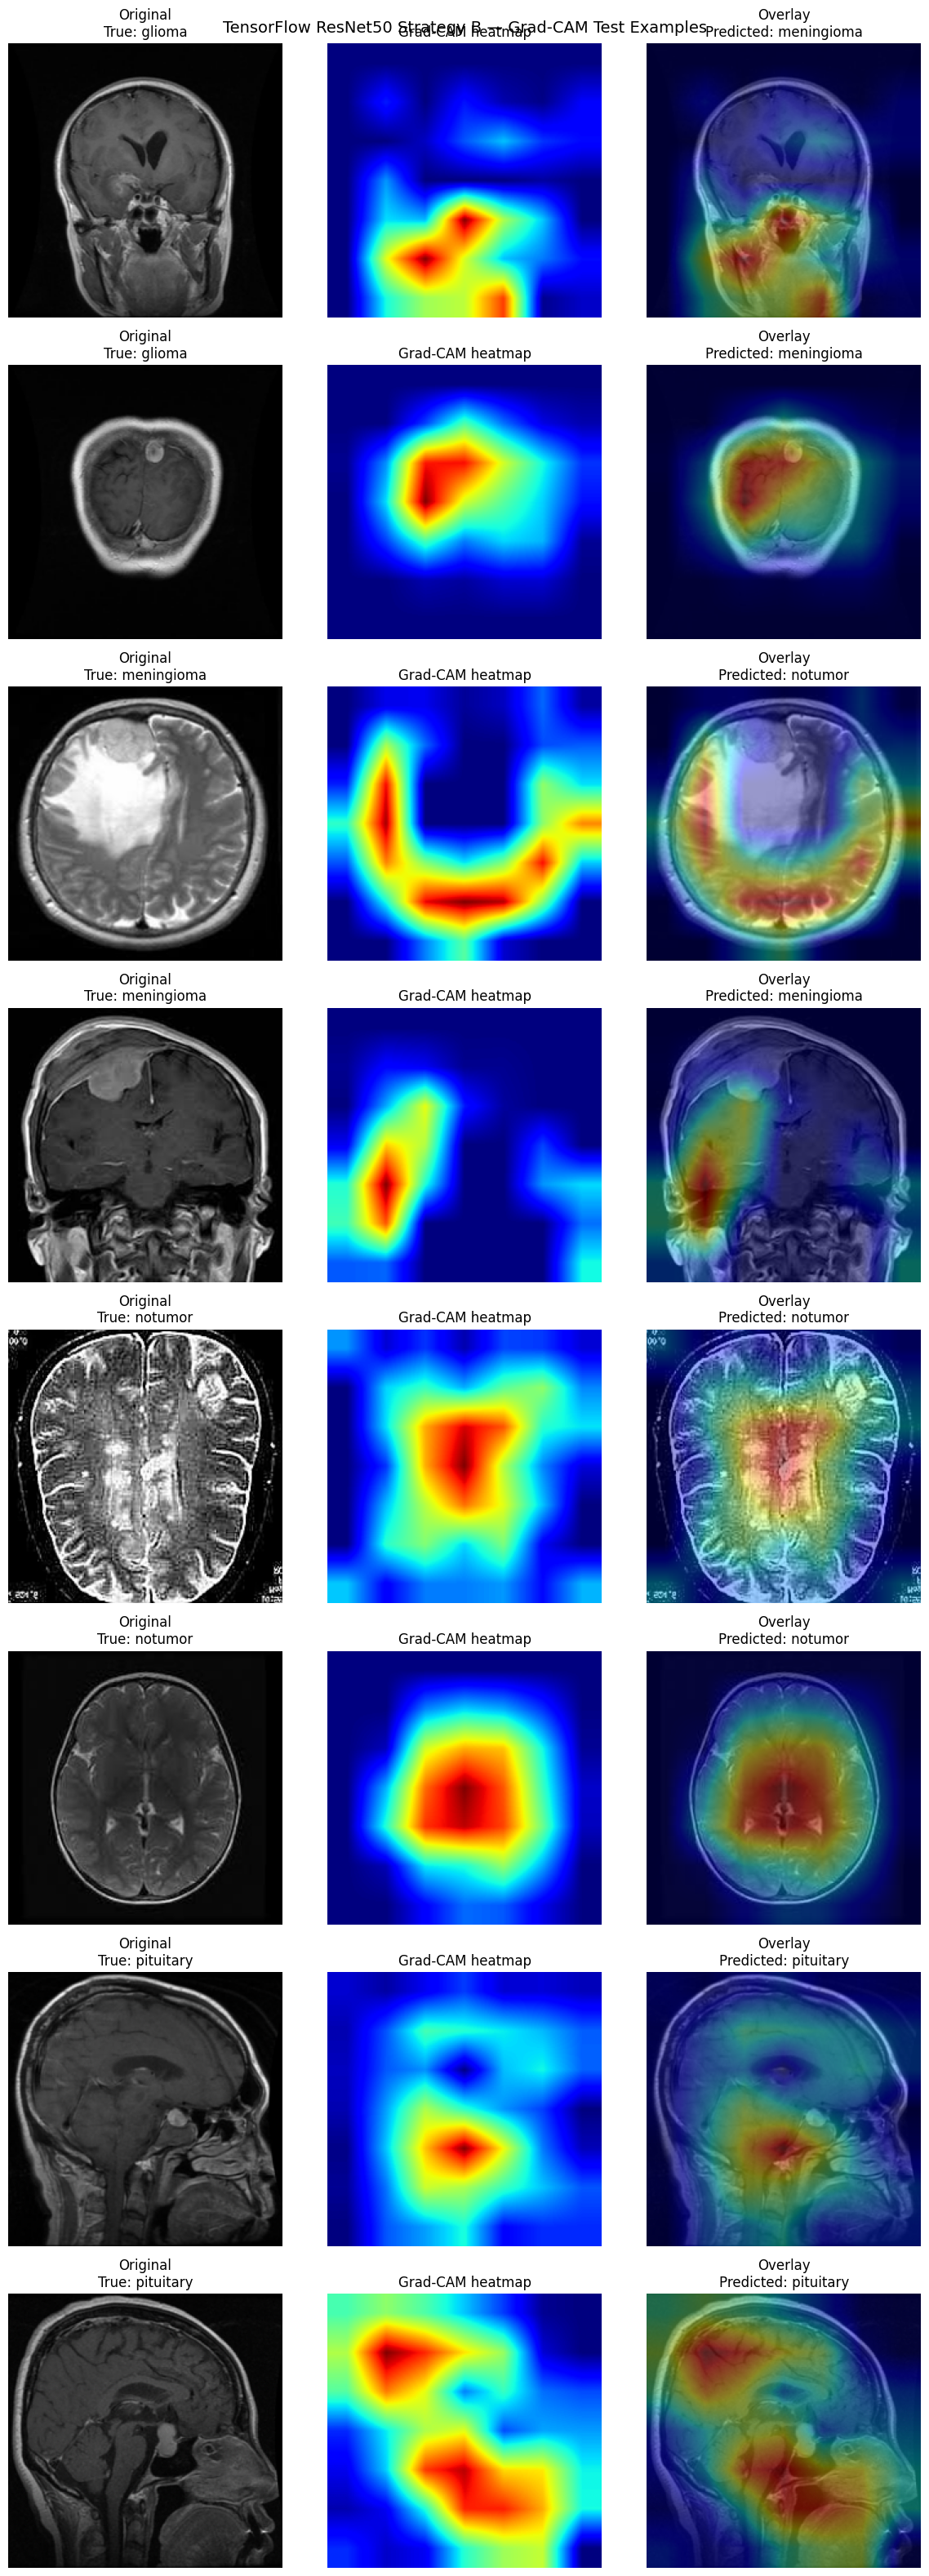

Saved Grad-CAM figure: /kaggle/working/tensorflow_gradcam_examples.png


In [18]:

import os
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from PIL import Image

CLASS_NAMES = ["glioma", "meningioma", "notumor", "pituitary"]
IMG_SIZE = 224

MODEL_PATH = "/kaggle/working/tensorflow_resnet50_strategy_b_best.keras"
SPLIT_CSV = "/kaggle/working/splits.csv"
OUTPUT_PATH = "/kaggle/working/tensorflow_gradcam_examples.png"

model = tf.keras.models.load_model(MODEL_PATH)
backbone = model.get_layer("resnet50")

# Build a model that returns the target convolutional features
# and the backbone's final feature vector in one connected graph.
cam_backbone = tf.keras.Model(
    inputs=backbone.inputs,
    outputs=[
        backbone.get_layer("conv5_block3_out").output,
        backbone.output
    ]
)

# Reuse the original trained classification head.
gap_layer = model.get_layer("global_average_pooling2d")
dropout_layer = model.get_layer("dropout")
classifier_layer = model.get_layer("dense")

def preprocess_image(path):
    image = Image.open(path).convert("RGB").resize((IMG_SIZE, IMG_SIZE))
    image = np.asarray(image, dtype=np.float32)
    return tf.keras.applications.resnet50.preprocess_input(image)

def make_gradcam(image_tensor):
    # Pass a tensor directly into the nested backbone.
    with tf.GradientTape() as tape:
        feature_maps, backbone_features = cam_backbone(
            tf.convert_to_tensor(image_tensor, dtype=tf.float32),
            training=False
        )
        tape.watch(feature_maps)

        # Replicate the trained classification head.
        x = gap_layer(backbone_features)
        x = dropout_layer(x, training=False)
        predictions = classifier_layer(x)

        predicted_class = tf.argmax(predictions[0])
        class_score = predictions[:, predicted_class]

    # Compute gradients of the predicted class score
    # with respect to the convolutional feature maps.
    gradients = tape.gradient(class_score, feature_maps)

    if gradients is None:
        raise RuntimeError(
            "Grad-CAM gradients are None. Check the backbone graph."
        )

    weights = tf.reduce_mean(gradients, axis=(1, 2))
    feature_maps = feature_maps[0]
    weights = weights[0]

    cam = tf.reduce_sum(
        feature_maps * weights[tf.newaxis, tf.newaxis, :],
        axis=-1
    )
    cam = tf.maximum(cam, 0)

    max_value = tf.reduce_max(cam)
    cam = tf.where(
        max_value > 0,
        cam / (max_value + 1e-8),
        tf.zeros_like(cam)
    )

    cam = tf.image.resize(
        cam[..., tf.newaxis],
        (IMG_SIZE, IMG_SIZE)
    )[..., 0]

    return cam.numpy(), int(predicted_class.numpy()), predictions[0].numpy()

# Select two test images from each class
df = pd.read_csv(SPLIT_CSV)
test_df = df[df["split"] == "test"].copy()

selected = []
for class_name in CLASS_NAMES:
    class_rows = test_df[test_df["label"] == class_name]
    selected.extend(class_rows.head(2).to_dict("records"))

fig, axes = plt.subplots(len(selected), 3, figsize=(12, 4 * len(selected)))

for i, row in enumerate(selected):
    path = row["path"]
    true_label = row["label"]

    image_tensor = preprocess_image(path)[np.newaxis, ...]
    heatmap, pred_idx, probabilities = make_gradcam(image_tensor)

    original = np.asarray(
        Image.open(path).convert("RGB").resize((IMG_SIZE, IMG_SIZE))
    )

    axes[i, 0].imshow(original)
    axes[i, 0].set_title(f"Original\nTrue: {true_label}")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(heatmap, cmap="jet", vmin=0, vmax=1)
    axes[i, 1].set_title("Grad-CAM heatmap")
    axes[i, 1].axis("off")

    axes[i, 2].imshow(original)
    axes[i, 2].imshow(heatmap, cmap="jet", alpha=0.4, vmin=0, vmax=1)
    axes[i, 2].set_title(f"Overlay\nPredicted: {CLASS_NAMES[pred_idx]}")
    axes[i, 2].axis("off")

plt.suptitle(
    "TensorFlow ResNet50 Strategy B — Grad-CAM Test Examples",
    fontsize=14
)
plt.tight_layout()
plt.savefig(OUTPUT_PATH, dpi=180, bbox_inches="tight")
plt.show()

print("Saved Grad-CAM figure:", OUTPUT_PATH)
